# Sanity check

Plot normalized intensity profiles over time for nuclei, faceted (wrapped) by treatment, with both channels overlaid on each panel.

In [1]:
suppressWarnings(suppressPackageStartupMessages(library(arrow)))
suppressWarnings(suppressPackageStartupMessages(library(dplyr)))
suppressWarnings(suppressPackageStartupMessages(library(ggplot2)))
suppressWarnings(suppressPackageStartupMessages(library(stringr)))
suppressWarnings(suppressPackageStartupMessages(library(tidyr)))

In [2]:
plate_name <- "plate_2"

# find the git root by walking up from the current working directory
find_git_root <- function(start_dir) {
    dir <- start_dir
    while (!dir.exists(file.path(dir, ".git"))) {
        parent <- dirname(dir)
        if (parent == dir) {
            stop("No Git root directory found.")
        }
        dir <- parent
    }
    dir
}
root_dir <- find_git_root(getwd())

# use the Bandicoot mount if it is available, otherwise fall back to the repo's data dir
bandicoot_mount_path <- file.path(Sys.getenv("HOME"), "mnt", "bandicoot")
if (dir.exists(bandicoot_mount_path)) {
    image_base_dir <- file.path(
        Sys.getenv("HOME"), "mnt", "bandicoot",
        "live_cell_timelapse_pyroptosis_project_data"
    )
} else {
    image_base_dir <- file.path(root_dir, "data")
}
image_base_dir <- file.path(image_base_dir, "processed_data")

In [3]:
norm_agg_profiles_path <- file.path(
    image_base_dir, "12.aggregate_profiles", plate_name,
    "aggregate_profiles_from_normalized.parquet"
)
norm_consensus_profiles_path <- file.path(
    image_base_dir, "12.aggregate_profiles", plate_name,
    "consensus_profiles_from_normalized.parquet"
)
fs_agg_profiles_path <- file.path(
    image_base_dir, "12.aggregate_profiles", plate_name,
    "aggregate_profiles_from_feature_selected.parquet"
)
fs_consensus_profiles_path <- file.path(
    image_base_dir, "12.aggregate_profiles", plate_name,
    "consensus_profiles_from_feature_selected.parquet"
)
dir.create(dirname(norm_agg_profiles_path), recursive = TRUE, showWarnings = FALSE)

In [4]:
norm_agg_df <- arrow::read_parquet(norm_agg_profiles_path)

In [5]:
head(norm_agg_df)

Metadata_Well,Metadata_Inducer1,Metadata_Inducer1_dose,Metadata_Inducer1_unit,Metadata_Inducer2,Metadata_Inducer2_dose,Metadata_Inducer2_unit,Metadata_Inhibitor,Metadata_Inhibitor_dose,Metadata_Inhibitor_unit,⋯,Nuclei_Texture_Variance_CL640_3_02_256,Nuclei_Texture_Variance_CL640_3_03_256,Nuclei_Texture_Variance_NucleoLive_3_00_256,Nuclei_Texture_Variance_NucleoLive_3_01_256,Nuclei_Texture_Variance_NucleoLive_3_02_256,Nuclei_Texture_Variance_NucleoLive_3_03_256,Nuclei_Texture_Variance_SYTOXGreen_3_00_256,Nuclei_Texture_Variance_SYTOXGreen_3_01_256,Nuclei_Texture_Variance_SYTOXGreen_3_02_256,Nuclei_Texture_Variance_SYTOXGreen_3_03_256
<chr>,<chr>,<dbl>,<chr>,<chr>,<dbl>,<chr>,<chr>,<dbl>,<chr>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
B2,DMSO,0.15,%,DMSO,0.15,%,DMSO,0.15,%,⋯,-0.3613290,-0.3503597,-0.1620240,-0.1618279,-0.1616167,-0.1617126,-0.1319034,-0.1316171,-0.1318682,-0.1317482
B2,DMSO,0.15,%,DMSO,0.15,%,DMSO,0.15,%,⋯,-0.4342754,-0.4154768,-0.1562606,-0.1559539,-0.1557402,-0.1557852,-0.1319034,-0.1316171,-0.1318682,-0.1317482
B2,DMSO,0.15,%,DMSO,0.15,%,DMSO,0.15,%,⋯,-0.3464486,-0.3518034,-0.1344651,-0.1335057,-0.1337216,-0.1333461,-0.1319034,-0.1316171,-0.1318682,-0.1317482
B2,DMSO,0.15,%,DMSO,0.15,%,DMSO,0.15,%,⋯,-0.3184593,-0.3077188,-0.1346077,-0.1337476,-0.1339706,-0.1335036,-0.1319034,-0.1316171,-0.1318682,-0.1317482
B2,DMSO,0.15,%,DMSO,0.15,%,DMSO,0.15,%,⋯,-0.2157670,-0.2054849,-0.1358872,-0.1351869,-0.1353167,-0.1351817,-0.1319034,-0.1316171,-0.1318682,-0.1317482
B2,DMSO,0.15,%,DMSO,0.15,%,DMSO,0.15,%,⋯,-0.1425666,-0.1184795,-0.1269166,-0.1259772,-0.1262436,-0.1261161,-0.1319034,-0.1316171,-0.1318682,-0.1317482


In [6]:
unique(norm_agg_df$Metadata_Well)

[1] "B2" "B3" "B4" "C2" "C3" "C4" "D2" "D3" "D4" "E2" "E3" "E4" "F2" "F3" "F4"
[16] "G2" "G3" "G4" "H2" "H3" "H4" "I2" "I3" "I4" "J2" "J3" "J4" "K2" "K3" "K4"
[31] "L2" "L3" "L4" "M2" "M3" "M4" "N2" "N3" "O2" "O3"

In [7]:
unique(norm_agg_df$Metadata_Inducer1)

[1] "DMSO"         "Thapsigargin" "Flagellin"    "UM5856"       "Nigericin"   
[6] "Staurosporin"

In [8]:
compartment <- "Nuclei"
channels <- c("NucleoLive", "SYTOXGreen")

# build a single treatment-combo label, e.g. "LPS 1ug/ml + Nigericin 1uM"
norm_agg_df <- norm_agg_df %>%
    mutate(
        inducer2_part = if_else(
            Metadata_Inducer2 != "DMSO",
            paste("+", Metadata_Inducer2, Metadata_Inducer2_dose),
            ""
        ),
        Metadata_Treatment_combo = stringr::str_squish(paste(
            Metadata_Inducer1, Metadata_Inducer1_dose,
            inducer2_part,
            "+", Metadata_Inhibitor, Metadata_Inhibitor_dose
        ))
    ) %>%
    select(-inducer2_part)

# sort treatments by the numeric dose values embedded in the label
dose_sort_key <- function(treatment) {
    doses <- as.numeric(str_extract_all(treatment, "[\\d.]+")[[1]])
    if (length(doses) == 0) doses <- 0
    # pad to a fixed width so treatments sort lexicographically on dose magnitude
    paste(sprintf("%020.6f", doses), collapse = "_")
}
treatment_order <- norm_agg_df %>%
    distinct(Metadata_Treatment_combo) %>%
    pull(Metadata_Treatment_combo)
treatment_order <- treatment_order[order(sapply(treatment_order, dose_sort_key))]
norm_agg_df$Metadata_Treatment_combo <- factor(
    norm_agg_df$Metadata_Treatment_combo,
    levels = treatment_order
)

In [9]:
#' Plot mean +/- SE intensity profiles over time, wrapped by treatment with
#' both channels overlaid on each panel
channel_colors <- c("NucleoLive" = "cyan", "SYTOXGreen" = "green")

plot_intensity_profiles <- function(df, compartment, channels, stat, stat_label, ncol = 4) {
    feature_cols <- paste(compartment, "Intensity", stat, channels, sep = "_")
    present <- feature_cols %in% colnames(df)
    feature_cols <- feature_cols[present]
    channels <- channels[present]

    long_df <- df %>%
        select(
            Metadata_Time, Metadata_Treatment_combo, all_of(feature_cols)
        ) %>%
        pivot_longer(
            cols = all_of(feature_cols),
            names_to = "Metadata_Channel",
            values_to = "Intensity"
        ) %>%
        mutate(
            Metadata_Channel = factor(
                feature_cols[match(Metadata_Channel, feature_cols)],
                labels = channels
            )
        )

    summary_df <- long_df %>%
        group_by(Metadata_Treatment_combo, Metadata_Channel, Metadata_Time) %>%
        summarise(
            mean_intensity = mean(Intensity, na.rm = TRUE),
            se_intensity = sd(Intensity, na.rm = TRUE) / sqrt(sum(!is.na(Intensity))),
            .groups = "drop"
        )

    ggplot(
        summary_df,
        aes(x = Metadata_Time, y = mean_intensity, color = Metadata_Channel)
    ) +
        geom_ribbon(
            aes(
                ymin = mean_intensity - se_intensity,
                ymax = mean_intensity + se_intensity,
                fill = Metadata_Channel
            ),
            alpha = 0.2, color = NA
        ) +
        geom_line(linewidth = 1) +
        facet_wrap(~Metadata_Treatment_combo, ncol = ncol) +
        scale_color_manual(values = channel_colors) +
        scale_fill_manual(values = channel_colors) +
        labs(
            title = paste(
                compartment, stat_label,
                "intensity profiles over time, by treatment"
            ),
            x = "Time",
            y = paste(stat_label, "intensity (normalized)"),
            color = "Channel",
            fill = "Channel"
        ) +
        theme_bw(base_size = 22) +
        theme(
            plot.title = element_text(size = 26, face = "bold"),
            axis.title = element_text(size = 24),
            axis.text = element_text(size = 18),
            strip.text = element_text(size = 20),
            legend.title = element_text(size = 22),
            legend.text = element_text(size = 20),
            legend.position = "bottom"
        )
}

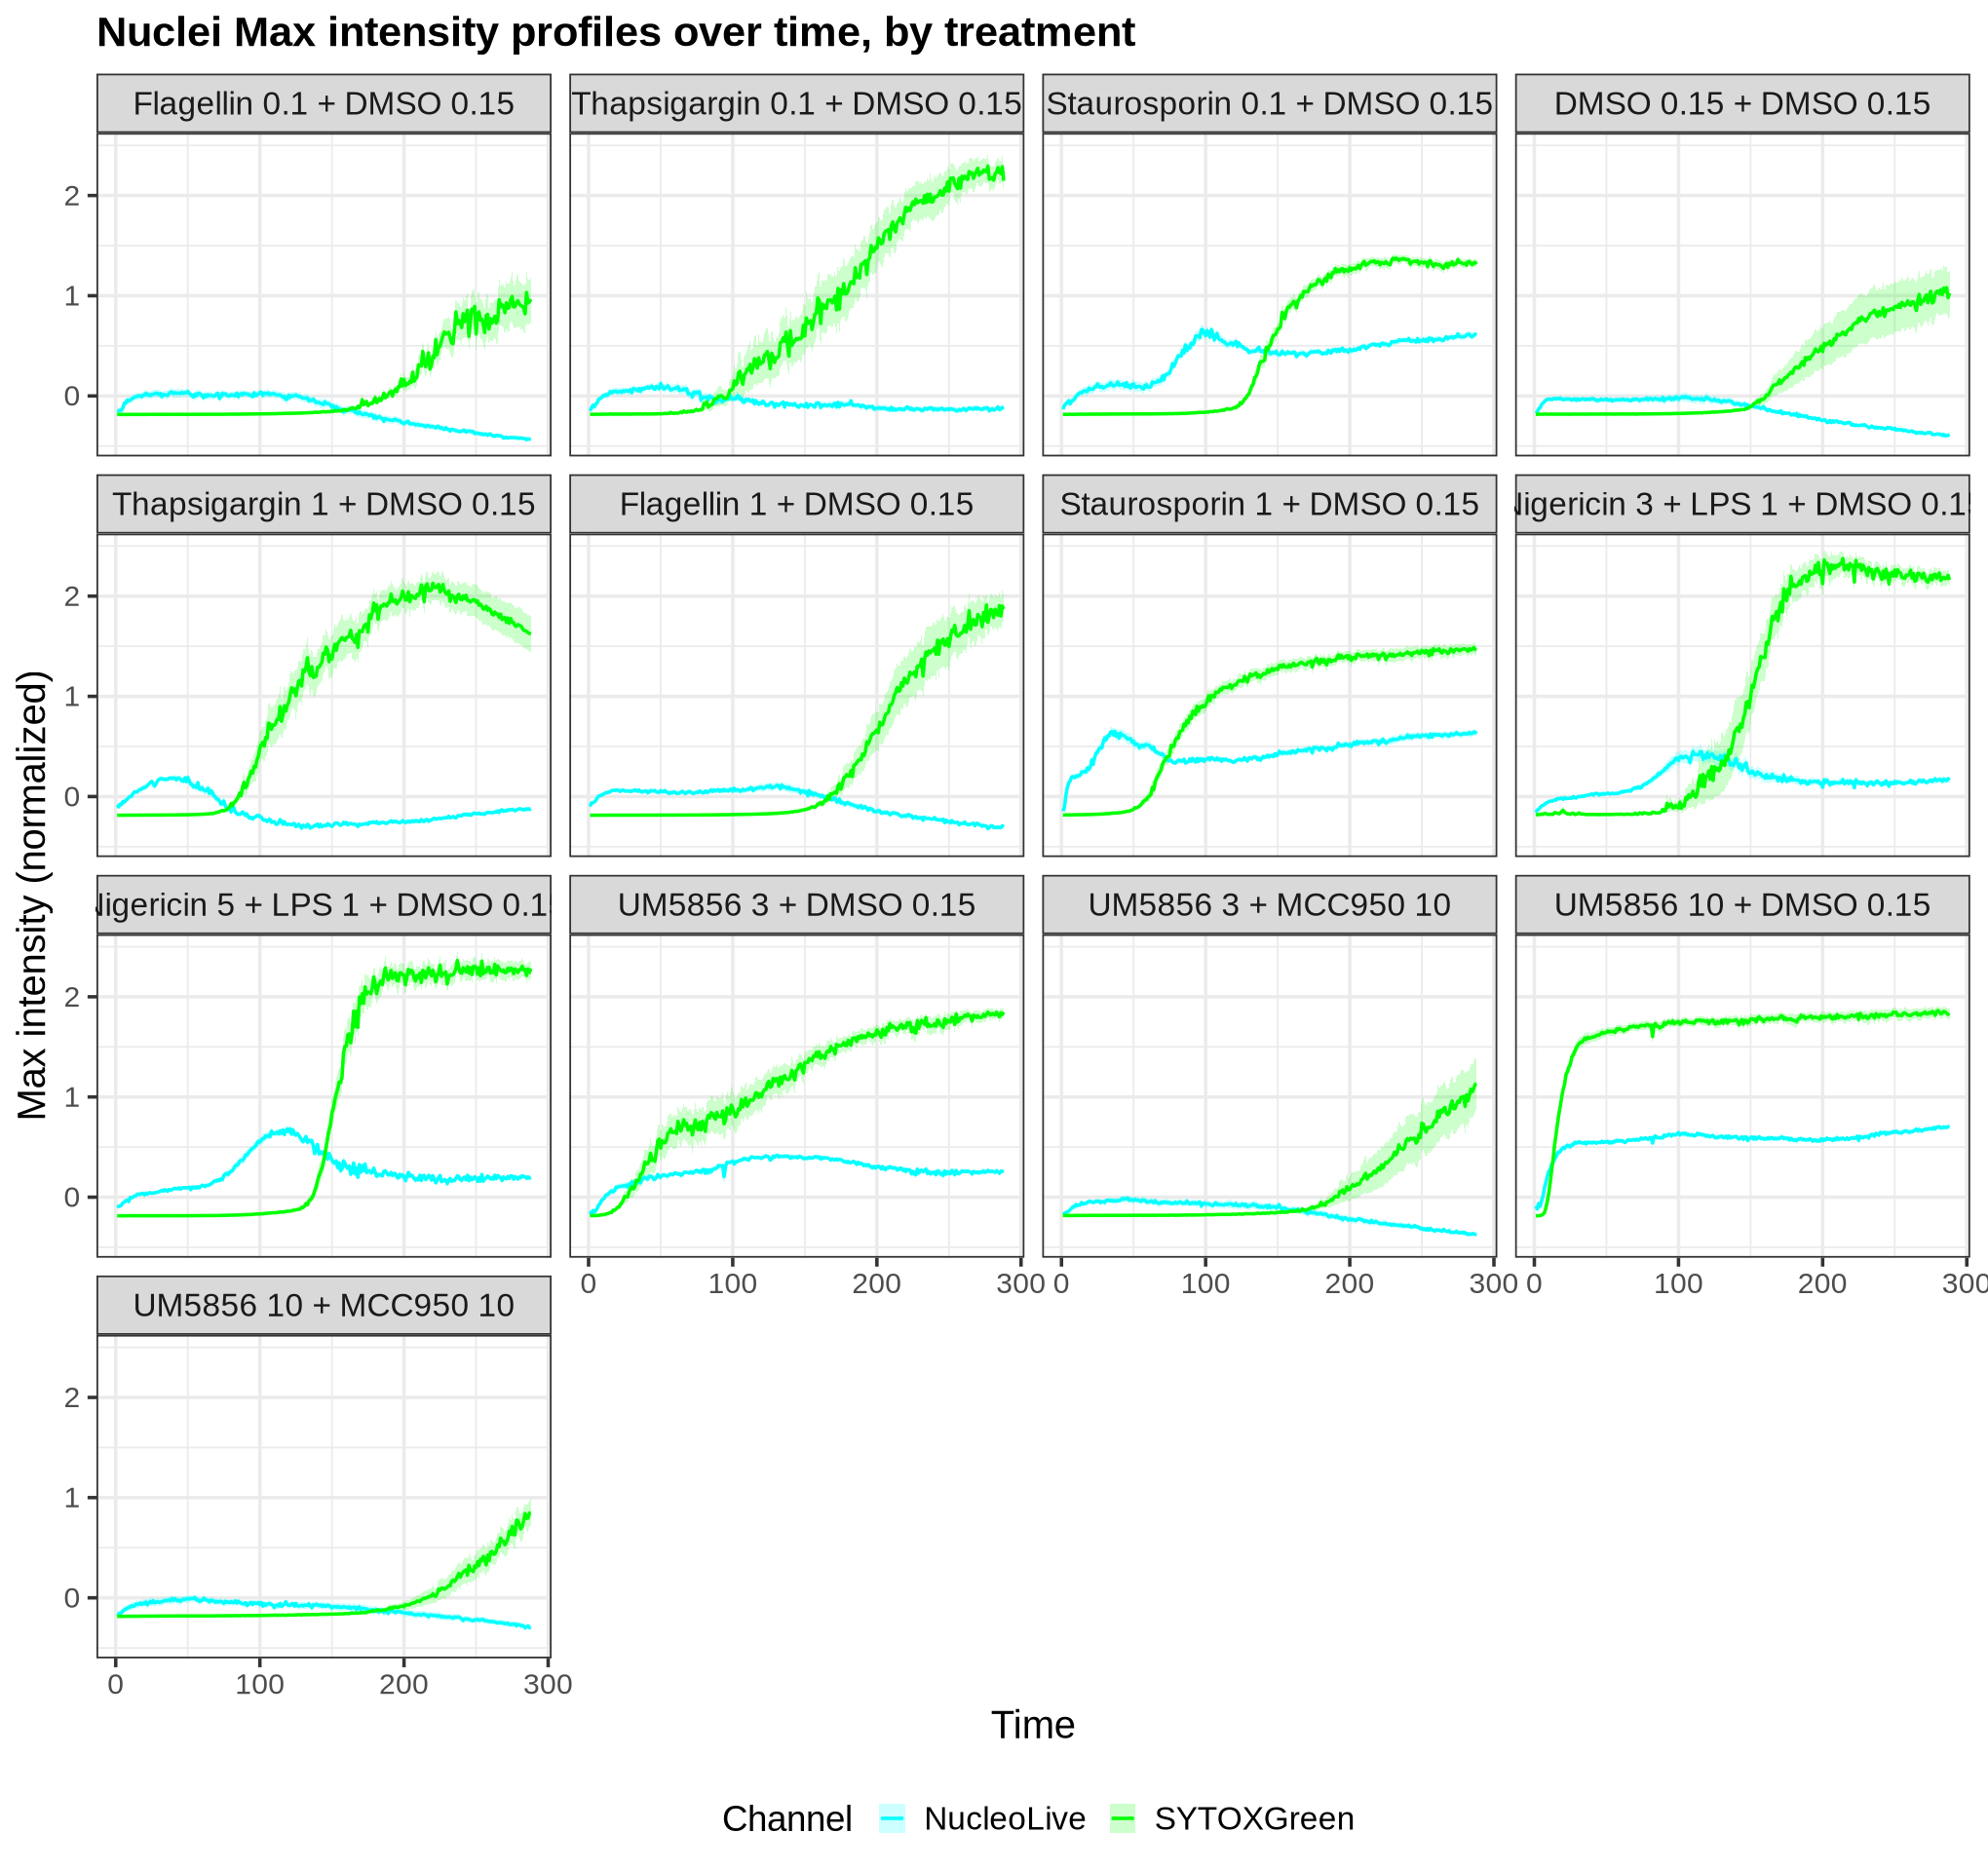

In [11]:
width <- 17
height <- 16
ncol <- 4
options(repr.plot.width = width, repr.plot.height = height)

max_intensity_plot <- plot_intensity_profiles(
    norm_agg_df, compartment, channels, "MaxIntensity", "Max", ncol = ncol
)
max_intensity_plot